# 102｜成本约束下的系统研究

CPU离线实验。先读lecture.md和lab.md，从本讲目录按序运行；重跑覆盖本目录outputs。

In [1]:
from pathlib import Path
import json, numpy as np
import experiment as e
print("Ready: CPU experiment")

Ready: CPU experiment


## 运行完整协议

不跳过失败配置，不将墙钟时间视为固定硬件保证。

In [2]:
e.main()

{
  "thresholds": {
    "all_accuracy_min": 0.9,
    "tail_accuracy_min": 0.8,
    "batch_response_p95_max_seconds": 0.002
  },
  "quality": [
    {
      "model": "w8_s11",
      "width": 8,
      "seed": 11,
      "accuracy": 0.9583333333333334,
      "common_accuracy": 0.9819341126461212,
      "tail_accuracy": 0.8725868725868726,
      "test_n": 1200,
      "tail_n": 259,
      "parameter_bytes": 168,
      "training_seconds": 5.928542734000075
    },
    {
      "model": "w8_s23",
      "width": 8,
      "seed": 23,
      "accuracy": 0.8433333333333334,
      "common_accuracy": 0.9319872476089267,
      "tail_accuracy": 0.5212355212355212,
      "test_n": 1200,
      "tail_n": 259,
      "parameter_bytes": 168,
      "training_seconds": 2.2281123459997616
    },
    {
      "model": "w8_s37",
      "width": 8,
      "seed": 37,
      "accuracy": 0.8458333333333333,
      "common_accuracy": 0.9287991498405951,
      "tail_accuracy": 0.5444015444015444,
      "test_n": 1200,
      "

In [3]:
metrics = json.loads(Path("outputs/metrics.json").read_text())
print("Result fields:", list(metrics))

Result fields: ['protocol', 'thresholds', 'quality', 'summary', 'feasible_pareto', 'training_seconds_total', 'replay_length', 'tail_replay_unique_examples', 'test_tail_n', 'cost_scope']


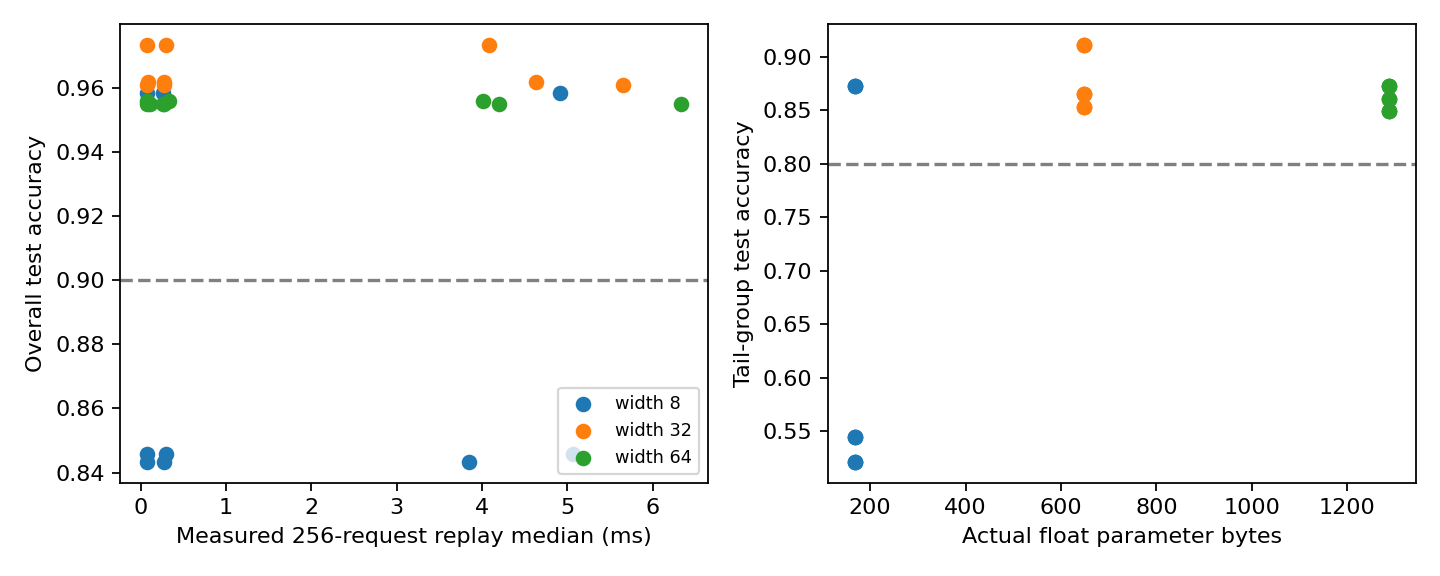

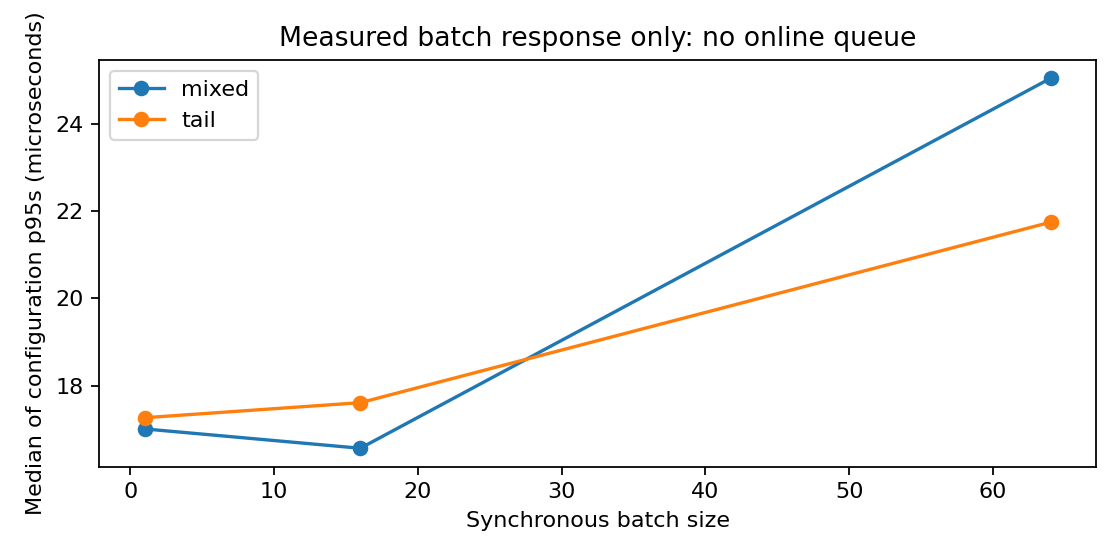

In [4]:
from IPython.display import display, Image
for path in sorted(Path("figures").glob("*.png")):
    display(Image(filename=str(path)))

## 独立断言

此处运行tests.py中的全部测试；失败必须先诊断，不能删除断言。

In [5]:
import unittest, tests
result=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromModule(tests))
assert result.wasSuccessful()

test_batch_timing_accounting (tests.Tests.test_batch_timing_accounting) ... 

ok


test_pareto (tests.Tests.test_pareto) ... 

ok


test_quality_recompute (tests.Tests.test_quality_recompute) ... 

...

test_summary_and_constraints (tests.Tests.test_summary_and_constraints) ... 

ok


test_threshold_boundary (tests.Tests.test_threshold_boundary) ... 

ok


----------------------------------------------------------------------
Ran 6 tests in 0.322s

OK


In [6]:
print("解释题：哪些结果是真实CPU测量？哪些属于模型假设？哪些结论需要新实验？")

解释题：哪些结果是真实CPU测量？哪些属于模型假设？哪些结论需要新实验？
